In [1]:
import numpy as np
from pathlib import Path
import os
import matplotlib.pyplot as plt

import torch

from sklearn.model_selection import train_test_split

from collections import Counter

from PIL import Image, ImageOps

from concurrent.futures import ThreadPoolExecutor

from tqdm.auto import tqdm

import pprint

In [2]:
print(f"Current working directory: {Path.cwd()}")
print(f"PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if device.type == "cuda":
    print(f"CUDA Available!\nGPU: {torch.cuda.get_device_name(0)}")
else:
    print(f"GPU unavailable. We should fix this before training.")

Current working directory: d:\Intelligent_farming_system\disease_detection
PyTorch version: 2.14.0+cu130
Selected device: cuda
CUDA Available!
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU


In [3]:
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "disease_dataset" / "processed"

CACHE_DIR = PROJECT_DIR / "disease_detection" /"cache"

In [4]:
print(f"Dataset exists: {DATASET_DIR.exists()}")
print(f"Cache exists: {CACHE_DIR.exists()}")

if DATASET_DIR.exists():
    print("Number of crop folders: ", len([
        p for p in DATASET_DIR.iterdir() if p.is_dir()
    ]))

Dataset exists: True
Cache exists: True
Number of crop folders:  18


In [5]:
records = []

for crop_dir in sorted(DATASET_DIR.iterdir()):
    if not crop_dir.is_dir():
        continue

    for disease_dir in sorted(crop_dir.iterdir()):
        if not disease_dir.is_dir():
            continue

        for image_path in sorted(disease_dir.rglob("*")):
            if image_path.is_file():
                records.append(
                    (image_path, crop_dir.name, disease_dir.name)
                )

In [6]:
print(f"Total images: {len(records)}")
print(f"Total crops: {len(set(r[1] for r in records))}")
print(f"First Record: \n{records[0]}")

Total images: 63664
Total crops: 18
First Record: 
(WindowsPath('d:/Intelligent_farming_system/disease_dataset/processed/banana/Bacterial_Soft_Rot/BACTERIAL_SOFT_ROT (1).jpg'), 'banana', 'Bacterial_Soft_Rot')


In [7]:
images_per_crop = Counter(record[1] for record in records)

for crop, count in sorted(images_per_crop.items()):
    print(f"{crop}: {count}")

print(f"\nTotal images: {sum(images_per_crop.values())}")

banana: 3502
chilli: 1412
cotton: 938
grape: 3477
groundnut: 1720
maize: 2476
mango: 2000
okra: 1495
paddy_doctor: 7371
pea: 11175
pigeon_pea: 824
pomegranate: 5099
potato: 15519
soybean: 499
sugarcane: 2521
tomato: 2133
turmeric: 644
wheat: 859

Total images: 63664


In [8]:
stratify_labels = [
    f"{crop}__{disease}"
    for _, crop, disease in records
]

In [9]:
train_records, temp_records = train_test_split(
    records,
    test_size=0.3,
    random_state=42,
    stratify=stratify_labels
)

In [10]:
temp_stratify_labes = [
    f"{crop}__{disease}"
    for _, crop, disease in temp_records
]

In [11]:
val_records, test_records = train_test_split(
    temp_records,
    test_size=0.5,
    random_state=42,
    stratify=temp_stratify_labes
)

In [12]:
print("Training:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))
print("Total:", len(train_records) + len(val_records) + len(test_records))

Training: 44564
Validation: 9550
Test: 9550
Total: 63664


In [13]:
def preprocess_image(index_record):

    index, record = index_record

    image_path, crop, disease = record

    with Image.open(image_path) as image:

        image = image.convert("RGB")

        image = ImageOps.pad(
            image,
            (128, 128),
            color=(0, 0, 0)
        )

        image_array = np.array(image, dtype=np.uint8)

    return index, image_array, crop, disease

In [14]:
test_result = preprocess_image((0, records[0]))

index, image_array, crop, disease = test_result


test_result = preprocess_image((0, records[0]))

index, image_array, crop, disease = test_result

print("Index:", index)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Crop:", crop)
print("Disease:", disease)
print("Pixel range:", image_array.min(), "to", image_array.max())


Index: 0
Image shape: (128, 128, 3)
Image data type: uint8
Crop: banana
Disease: Bacterial_Soft_Rot
Pixel range: 0 to 255


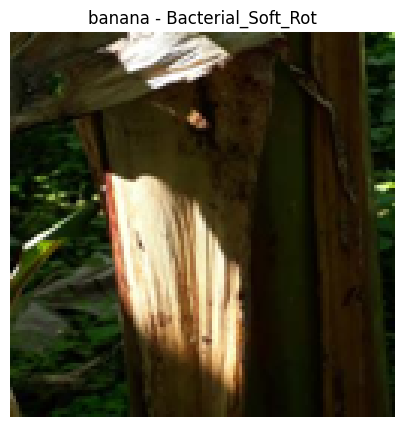

In [15]:
plt.figure(figsize=(5, 5))
plt.imshow(image_array)
plt.title(f"{crop} - {disease}")
plt.axis("off")
plt.show()

Original dimensions: (256, 256)
Processed dimensions: (128, 128)


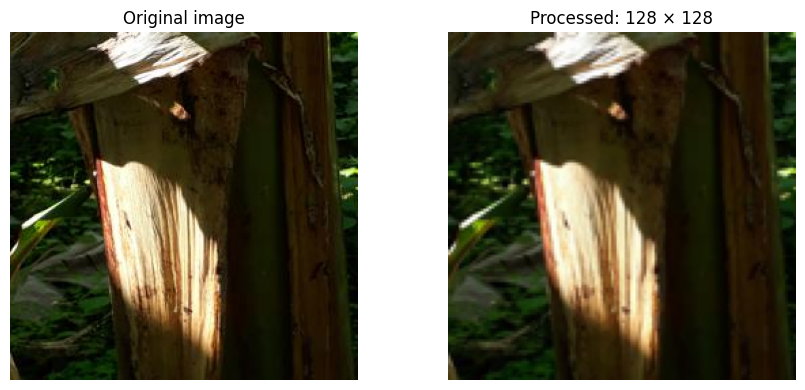

In [16]:

image_path = records[0][0]

with Image.open(image_path) as original:
    print("Original dimensions:", original.size)

print("Processed dimensions:", image_array.shape[:2][::-1])

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(Image.open(image_path).convert("RGB"))
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_array)
plt.title("Processed: 128 × 128")
plt.axis("off")

plt.tight_layout()
plt.show()


Image: <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=191x229 at 0x20AF2D54B90>
Image: d:\Intelligent_farming_system\disease_dataset\processed\banana\Black_Sigatoka\BLACK_SIGATOKA 0001 417 .jpg
Original dimensions: (191, 229)


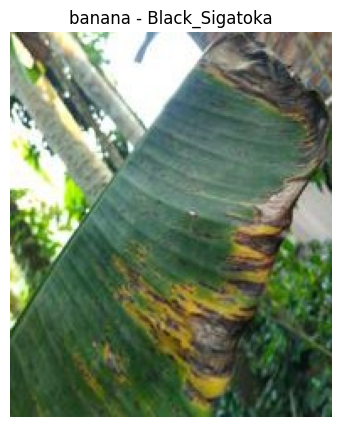

In [17]:
for record in records:
    with Image.open(record[0]) as image:
        if image.height != image.width:
            print(f"Image: {image}")
            print(f"Image: {record[0]}")

            print("Original dimensions:", image.size)

            plt.figure(figsize=(5, 5))
            plt.imshow(image)
            plt.title(f"{record[1]} - {record[2]}")
            plt.axis("off")
            plt.show()

            break

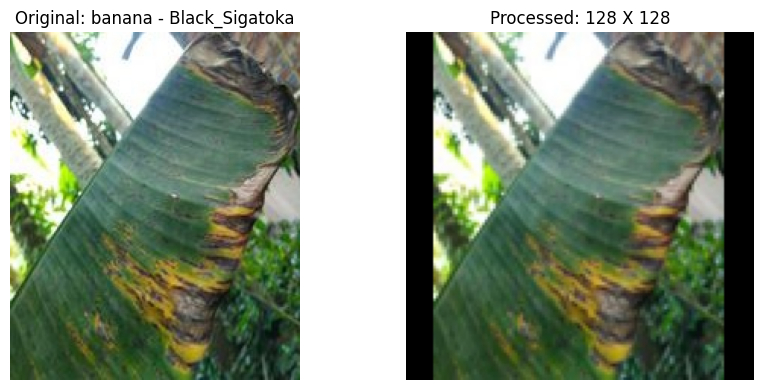

In [18]:
test_record = record

test_result = preprocess_image((0, test_record))

_, padded_array, crop, disease = test_result

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
with Image.open(test_record[0]) as image:
    plt.imshow(image.convert("RGB"))
plt.title(f"Original: {crop} - {disease}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(padded_array)
plt.title("Processed: 128 X 128")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:

CACHE_DIR = PROJECT_DIR / "disease_detection" / "cache"

train_cache = CACHE_DIR / "train_images.npy"
val_cache = CACHE_DIR / "val_images.npy"

print("Cache directory:", CACHE_DIR)
print("Training cache exists:", train_cache.exists())
print("Validation cache exists:", val_cache.exists())
print("Training cache size (GB):", round(train_cache.stat().st_size / (1024**3), 2) if train_cache.exists() else "Missing")
print("Validation cache size (GB):", round(val_cache.stat().st_size / (1024**3), 2) if val_cache.exists() else "Missing")


Cache directory: d:\Intelligent_farming_system\disease_detection\cache
Training cache exists: True
Validation cache exists: True
Training cache size (GB): 2.04
Validation cache size (GB): 0.44


In [20]:
crops = sorted({crop for _, crop, _ in records})

crop_to_index = {
    crop: index
    for index, crop in enumerate(crops)
}

disease_to_index = {}

for crop in crops:

    diseases = sorted({
        disease
        for _, record_crop, disease in records
        if record_crop == crop
    })

    disease_to_index[crop] = {
        disease: index
        for index, disease in enumerate(diseases)
    }

print(f"Number of crops: {len(crops)}")
print("Crop mapping:")
pprint.pprint(crop_to_index, width=20)

print("Number of disease classes: ", sum(
    len(mapping) for mapping in disease_to_index.values()
))

pprint.pprint(disease_to_index, width=20)

Number of crops: 18
Crop mapping:
{'banana': 0,
 'chilli': 1,
 'cotton': 2,
 'grape': 3,
 'groundnut': 4,
 'maize': 5,
 'mango': 6,
 'okra': 7,
 'paddy_doctor': 8,
 'pea': 9,
 'pigeon_pea': 10,
 'pomegranate': 11,
 'potato': 12,
 'soybean': 13,
 'sugarcane': 14,
 'tomato': 15,
 'turmeric': 16,
 'wheat': 17}
Number of disease classes:  82
{'banana': {'Bacterial_Soft_Rot': 0,
            'Black_Sigatoka': 1,
            'Healthy': 2,
            'Panama_Disease': 3,
            'Yellow_Sigatoka': 4},
 'chilli': {'Bacterial_Spot': 0,
            'Cercospora_Leaf_Spot': 1,
            'Curl_Virus': 2,
            'Healthy': 3,
            'White_Spot': 4},
 'cotton': {'Bacterial_Blight': 0,
            'Curl_Virus': 1,
            'Healthy': 2},
 'grape': {'Black_Rot': 0,
           'Esca': 1,
           'Healthy': 2,
           'Leaf_Blight': 3},
 'groundnut': {'Alternaria_Leaf_Spot': 0,
               'Healthy': 1,
               'Leaf_Spot_Early_Late': 2,
               'Rosette': 3,
  

In [21]:
def create_labels(split_records):

    crop_labels = np.array([
        crop_to_index[crop]
        for _, crop, disease in split_records
    ], dtype=np.int64)

    disease_labels = np.array([
        disease_to_index[crop][disease]
        for _, crop, disease in split_records
    ], dtype=np.int64)

    return crop_labels, disease_labels

In [22]:
train_crop_labels, train_disease_labels = create_labels(train_records)

val_crop_labels, val_disease_labels = create_labels(val_records)

In [23]:
print("Training crop labels:", train_crop_labels.shape)
print("Training disease labels:", train_disease_labels.shape)
print("Validation crop labels:", val_crop_labels.shape)
print("Validation disease labels:", val_disease_labels.shape)

Training crop labels: (44564,)
Training disease labels: (44564,)
Validation crop labels: (9550,)
Validation disease labels: (9550,)


In [24]:
TRAIN_IMAGES_CACHE = CACHE_DIR / "resnet18_train_images.npy"

VAL_IMAGES_CACHE = CACHE_DIR / "resnet18_val_images.npy"

In [25]:
print("Training cache: ", TRAIN_IMAGES_CACHE.resolve())
print("Validation cache: ", VAL_IMAGES_CACHE.resolve())

print("Training cache already exists:", TRAIN_IMAGES_CACHE.exists())
print("Validation cache already exists:", VAL_IMAGES_CACHE.exists())

Training cache:  D:\Intelligent_farming_system\disease_detection\cache\resnet18_train_images.npy
Validation cache:  D:\Intelligent_farming_system\disease_detection\cache\resnet18_val_images.npy
Training cache already exists: True
Validation cache already exists: True


In [26]:
def preprocess_cache_image(record):
    image_path, crop, disease = record

    with Image.open(image_path) as image:
        image = image.convert("RGB")

        image = ImageOps.pad(
            image,
            (128, 128),
            color=(0, 0, 0)
        )

        image_array = np.array(image, dtype=np.uint8)

    return image_array

In [27]:

if TRAIN_IMAGES_CACHE.exists():
    print(f"Training cache already exists: {TRAIN_IMAGES_CACHE}")
    print("Skipping preprocessing.")

else:
    temp_path = TRAIN_IMAGES_CACHE.with_name(
        "resnet18_train_images.building.npy"
    )

    train_images = None

    try:
        train_images = np.lib.format.open_memmap(
            temp_path,
            mode="w+",
            dtype=np.uint8,
            shape=(len(train_records), 128, 128, 3)
        )

        with ThreadPoolExecutor() as executor:
            for i, image_array in enumerate(tqdm(
                executor.map(preprocess_cache_image, train_records),
                total=len(train_records),
                desc="Preprocessing training images"
            )):
                train_images[i] = image_array

        train_images.flush()
        del train_images
        train_images = None

        temp_path.replace(TRAIN_IMAGES_CACHE)

        print("Training cache created successfully.")

    except Exception:
        if train_images is not None:
            del train_images

        temp_path.unlink(missing_ok=True)
        raise


Training cache already exists: d:\Intelligent_farming_system\disease_detection\cache\resnet18_train_images.npy
Skipping preprocessing.


In [28]:
train_images = np.load(TRAIN_IMAGES_CACHE, mmap_mode="r")

print(f"Shape: {train_images.shape}")
print(f"Data Type: {train_images.dtype}")
print(f"First image pixel range: {train_images[0].min()} - {train_images[0].max()}")
print(f"Last image shape: {train_images[-1].shape}")

Shape: (44564, 128, 128, 3)
Data Type: uint8
First image pixel range: 0 - 255
Last image shape: (128, 128, 3)


In [29]:
print(f"Validation cache pathe: {VAL_IMAGES_CACHE}")
print(f"Already exists: {VAL_IMAGES_CACHE.exists()}")

Validation cache pathe: d:\Intelligent_farming_system\disease_detection\cache\resnet18_val_images.npy
Already exists: True


In [30]:

np.save(CACHE_DIR / "resnet18_train_crop_labels.npy", train_crop_labels)
np.save(CACHE_DIR / "resnet18_train_disease_labels.npy", train_disease_labels)

np.save(CACHE_DIR / "resnet18_val_crop_labels.npy", val_crop_labels)
np.save(CACHE_DIR / "resnet18_val_disease_labels.npy", val_disease_labels)

print("All ResNet-18 label arrays saved successfully.")


All ResNet-18 label arrays saved successfully.


In [31]:

if VAL_IMAGES_CACHE.exists():
    print(f"Validation cache already exists: {VAL_IMAGES_CACHE}")
    print("Skipping cache creation.")

else:
    temp_path = VAL_IMAGES_CACHE.with_name(
        "resnet18_val_images.building.npy"
    )

    val_images = None

    try:
        val_images = np.lib.format.open_memmap(
            temp_path,
            mode="w+",
            dtype=np.uint8,
            shape=(len(val_records), 128, 128, 3)
        )

        with ThreadPoolExecutor() as executor:
            for i, image_array in enumerate(tqdm(
                executor.map(preprocess_cache_image, val_records),
                total=len(val_records),
                desc="Preprocessing validation images"
            )):
                val_images[i] = image_array

        val_images.flush()
        del val_images
        val_images = None

        temp_path.replace(VAL_IMAGES_CACHE)

        print("Validation cache created successfully.")

    except Exception:
        if val_images is not None:
            del val_images

        temp_path.unlink(missing_ok=True)
        raise


Validation cache already exists: d:\Intelligent_farming_system\disease_detection\cache\resnet18_val_images.npy
Skipping cache creation.


In [32]:
cache_checks = [
    (
        "Training",
        TRAIN_IMAGES_CACHE,
        train_records,
        train_crop_labels,
        train_disease_labels
    ),
    (
        "Validation",
        VAL_IMAGES_CACHE,
        val_records,
        val_crop_labels,
        val_disease_labels
    )
]

for name, cache_path, split_records, crop_labels, disease_labels in cache_checks:

    print(f"\n{name} cache verification")

    assert cache_path.exists(), f"{name} cache is missing!"

    images = np.load(cache_path, mmap_mode="r")

    expected_shape = (len(split_records), 128, 128, 3)

    assert images.shape == expected_shape, (
        f"{name} cache shape mismatch: "
        f"Expected {expected_shape}, got {images.shape}"
    )

    assert images.dtype == np.uint8, (
        f"{name} cache must have dtype uint8, got {images.dtype}"
    )

    assert len(crop_labels) == len(split_records)
    assert len(disease_labels) == len(split_records)

    sample_indices = sorted(set([
        0,
        len(split_records) // 2,
        len(split_records) - 1
    ]))

    for index in sample_indices:
        expected_image = preprocess_cache_image(split_records[index])

        assert np.array_equal(images[index], expected_image), (
            f"{name} image-record mismatch at index {index}"
        )

    print("Cache exists: Yes")
    print("Shape:", images.shape)
    print("Data type:", images.dtype)
    print("Crop labels:", crop_labels.shape)
    print("Disease labels:", disease_labels.shape)
    print("Image-record alignment: Verified")
    print("Status: PASSED")

print("\nAll ResNet-18 cache checks passed successfully.")


Training cache verification
Cache exists: Yes
Shape: (44564, 128, 128, 3)
Data type: uint8
Crop labels: (44564,)
Disease labels: (44564,)
Image-record alignment: Verified
Status: PASSED

Validation cache verification
Cache exists: Yes
Shape: (9550, 128, 128, 3)
Data type: uint8
Crop labels: (9550,)
Disease labels: (9550,)
Image-record alignment: Verified
Status: PASSED

All ResNet-18 cache checks passed successfully.
